In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path
import os

ROOT = Path("/content/drive/MyDrive/TP-PSI-G8-karo_03")

assert (ROOT / "src" / "enhance.py").exists(), (
    "No encontramos el repositorio. Revisá la ruta ROOT."
)

os.chdir(ROOT)
print("Estamos trabajando en:", Path.cwd())

Estamos trabajando en: /content/drive/MyDrive/TP-PSI-G8-karo_03


# Etapa 5 — Segmentación

## Objetivo
Convertir los mapas de características en una máscara de vasos.

## Primera prueba
Se aplica Otsu sobre PC3 dentro del campo de visión automático.
Esta prueba comprueba el funcionamiento del código en una imagen;
todavía no incorpora el mejoramiento y el realce definitivos
de las etapas 3 y 4, ni permite elegir el método final.

In [ ]:
%%writefile src/segment.py
"""Funciones para obtener máscaras de vasos."""

import numpy as np
from skimage.filters import threshold_otsu


def segmentar_otsu(mapa, campo):
    """Segmenta un mapa con vasos claros dentro del campo de visión."""
    mapa = np.asarray(mapa)
    campo = np.asarray(campo, dtype=bool)

    valores = mapa[campo]

    if valores.size == 0:
        raise ValueError("El campo de visión está vacío.")

    umbral = threshold_otsu(valores)
    mascara = (mapa > umbral) & campo

    return mascara, float(umbral)

Overwriting src/segment.py


In [ ]:
!python scripts/download_data.py

Descargando https://www5.cs.fau.de/fileadmin/research/datasets/fundus-images/all.zip
Descarga completa.


In [ ]:
import importlib
import src.segment as segment

importlib.reload(segment)

from src.data import dev_ids, load_image, load_vessels
from src.enhance import prepare_maps

imagen_id = dev_ids()[0]

foto = load_image(imagen_id)
referencia = load_vessels(imagen_id)

mapas, campo_auto, diametro = prepare_maps(
    foto, ["PC3"], factor=1
)

mascara, umbral = segment.segmentar_otsu(
    mapas["PC3"], campo_auto
)

print("Imagen:", imagen_id)
print("Umbral de Otsu:", round(umbral, 4))

Imagen: 01_h
Umbral de Otsu: 0.0057


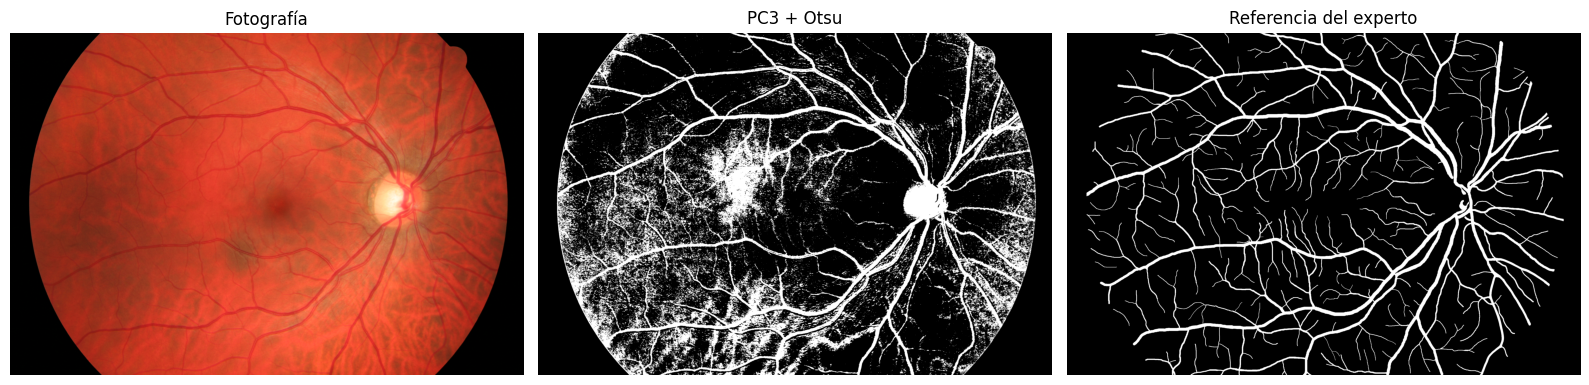

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(foto)
axes[0].set_title("Fotografía")

axes[1].imshow(mascara, cmap="gray")
axes[1].set_title("PC3 + Otsu")

axes[2].imshow(referencia, cmap="gray")
axes[2].set_title("Referencia del experto")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from src.data import load_fov
from src.metrics import matthews, dice

campo_ref = load_fov(imagen_id)

print("Matthews:", round(matthews(mascara, referencia, campo_ref), 4))
print("Dice:", round(dice(mascara, referencia, campo_ref), 4))

Matthews: 0.404
Dice: 0.4666


In [ ]:
%%writefile tests/test_segment.py
"""Pruebas de la segmentación por Otsu."""

import numpy as np
from src.segment import segmentar_otsu


def test_otsu_separa_vasos_y_excluye_exterior():
    """Detecta una línea clara sin incluir píxeles fuera del campo."""
    mapa = np.zeros((10, 10))
    mapa[:, 5] = 1
    mapa[:, 0] = 100  # Exterior brillante: no debe afectar el umbral.

    campo = np.ones((10, 10), dtype=bool)
    campo[:, 0] = False

    esperado = np.zeros((10, 10), dtype=bool)
    esperado[:, 5] = True

    mascara, _ = segmentar_otsu(mapa, campo)

    np.testing.assert_array_equal(mascara, esperado)

Writing tests/test_segment.py


In [ ]:
!python -m pytest -q

........................................................................ [ 62%]
...........................................                              [100%]
115 passed in 16.38s


## Referencia inicial en las 30 imágenes de desarrollo

Se evalúa PC3 con Otsu, sin mejoramiento, realce ni limpieza.
El umbral se calcula automáticamente para cada imagen.

Se mide Matthews y Dice dentro del campo de visión de referencia.
Estos resultados son una referencia inicial, no la selección del
algoritmo final.

In [ ]:
import pandas as pd
from src.config import RESULTS_DIR

filas = []
ids = dev_ids()

for numero, imagen_id in enumerate(ids, start=1):
    foto = load_image(imagen_id)
    referencia = load_vessels(imagen_id)
    campo_ref = load_fov(imagen_id)

    mapas, campo_auto, _ = prepare_maps(
        foto, ["PC3"], factor=1
    )

    mascara, umbral = segment.segmentar_otsu(
        mapas["PC3"], campo_auto
    )

    filas.append({
        "Imagen": imagen_id,
        "Método": "PC3 + Otsu sin preprocesamiento",
        "Umbral": umbral,
        "Matthews": matthews(mascara, referencia, campo_ref),
        "Dice": dice(mascara, referencia, campo_ref),
    })

    print(f"{numero}/{len(ids)} terminada: {imagen_id}")

tabla_inicial = pd.DataFrame(filas)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
tabla_inicial.to_csv(
    RESULTS_DIR / "05_referencia_pc3_otsu.csv",
    index=False
)

display(tabla_inicial.round(4))

1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g


,Imagen,Método,Umbral,Matthews,Dice
0,01_h,PC3 + Otsu sin preprocesamiento,0.0057,0.4040,0.4666
1,02_h,PC3 + Otsu sin preprocesamiento,-0.0002,0.2480,0.3184
2,03_h,PC3 + Otsu sin preprocesamiento,-0.0009,0.2100,0.3065
3,04_h,PC3 + Otsu sin preprocesamiento,-0.0006,0.2054,0.2858
4,07_h,PC3 + Otsu sin preprocesamiento,0.0001,0.2635,0.3099
5,08_h,PC3 + Otsu sin preprocesamiento,-0.0000,0.2525,0.3245
6,09_h,PC3 + Otsu sin preprocesamiento,-0.0071,0.1209,0.2039
7,10_h,PC3 + Otsu sin preprocesamiento,-0.0019,0.2028,0.2630
8,13_h,PC3 + Otsu sin preprocesamiento,0.0007,0.2633,0.3119
9,14_h,PC3 + Otsu sin preprocesamiento,0.0012,0.2730,0.3218


In [ ]:
resumen_inicial = tabla_inicial[["Matthews", "Dice"]].agg(
    ["mean", "std", "min", "max"]
).rename(index={
    "mean": "Media",
    "std": "Desvío",
    "min": "Mínimo",
    "max": "Máximo",
})

display(resumen_inicial.round(4))

,Matthews,Dice
Media,0.2454,0.2847
Desvío,0.0528,0.0527
Mínimo,0.1209,0.1947
Máximo,0.4040,0.4666


### Conclusión de la referencia inicial

En las 30 imágenes de desarrollo, PC3 + Otsu sin preprocesamiento
obtuvo Matthews medio de 0,2454 y Dice medio de 0,2847.

En el ejemplo visual se reconocen vasos principales, pero aparecen
falsos positivos en el fondo y faltan vasos finos. Se conserva esta
versión como referencia inicial para comparar las mejoras posteriores,
sin considerarla el algoritmo final.

## Segmentación con corrección del fondo

Se aplica corrección del fondo a PC3 antes de calcular el umbral
de Otsu. Se compara con PC3 + Otsu sin preprocesamiento en las
mismas 30 imágenes de desarrollo.

Se utiliza la escala explorada en la etapa 3: sigma igual a 0,02
veces el diámetro del campo de visión. Todavía no se incorpora
el filtro de realce de la etapa 4.

In [ ]:
%%writefile src/preprocess.py
"""Preprocesamiento de los mapas de características."""

import numpy as np
from scipy.ndimage import gaussian_filter


def corregir_fondo(mapa, campo, sigma):
    """Resta un fondo suave estimado dentro del campo de visión."""
    mapa = np.asarray(mapa, dtype=np.float32)
    campo = np.asarray(campo, dtype=bool)

    numerador = gaussian_filter(
        np.where(campo, mapa, 0.0), sigma=sigma
    )
    denominador = gaussian_filter(
        campo.astype(np.float32), sigma=sigma
    )

    fondo = numerador / np.maximum(denominador, 1e-8)
    return mapa - fondo

Writing src/preprocess.py


In [ ]:
from src.preprocess import corregir_fondo

filas_fondo = []

# Parámetro explorado en el punto 3.
sigma_rel = 0.02

for numero, imagen_id in enumerate(ids, start=1):
    foto = load_image(imagen_id)
    referencia = load_vessels(imagen_id)
    campo_ref = load_fov(imagen_id)

    mapas, campo_auto, diametro = prepare_maps(
        foto, ["PC3"], factor=1
    )

    corregido = corregir_fondo(
        mapas["PC3"],
        campo_auto,
        sigma=sigma_rel * diametro,
    )

    mascara, umbral = segment.segmentar_otsu(
        corregido, campo_auto
    )

    filas_fondo.append({
        "Imagen": imagen_id,
        "Método": "PC3 + corrección del fondo + Otsu",
        "Umbral": umbral,
        "Matthews": matthews(mascara, referencia, campo_ref),
        "Dice": dice(mascara, referencia, campo_ref),
    })

    print(f"{numero}/{len(ids)} terminada: {imagen_id}")

tabla_fondo = pd.DataFrame(filas_fondo)

tabla_fondo.to_csv(
    RESULTS_DIR / "05_pc3_fondo_otsu.csv",
    index=False
)

comparacion = pd.concat(
    [tabla_inicial, tabla_fondo],
    ignore_index=True
)

display(
    comparacion.groupby("Método")[["Matthews", "Dice"]]
    .mean()
    .round(4)
)

1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g


,Matthews,Dice
Método,,
PC3 + Otsu sin preprocesamiento,0.2454,0.2847
PC3 + corrección del fondo + Otsu,0.3180,0.3473


### Resultado de la corrección del fondo

Al incorporar corrección del fondo antes de Otsu, Matthews medio
aumentó de 0,2454 a 0,3180 y Dice medio de 0,2847 a 0,3473
en las 30 imágenes de desarrollo.

El resultado muestra una mejora descriptiva respecto de la referencia
inicial. Todavía falta incorporar el realce de la etapa 4 y comparar
las alternativas de segmentación.

In [ ]:
%%writefile tests/test_preprocess.py
"""Pruebas de la corrección del fondo."""

import numpy as np
from src.preprocess import corregir_fondo


def test_fondo_constante_y_exterior_excluido():
    """Un campo uniforme queda en cero, aunque el exterior sea brillante."""
    campo = np.zeros((20, 20), dtype=bool)
    campo[4:16, 4:16] = True

    mapa = np.full((20, 20), 100.0)
    mapa[campo] = 3.0

    resultado = corregir_fondo(mapa, campo, sigma=2)

    np.testing.assert_allclose(
        resultado[campo], 0, atol=1e-5
    )

Writing tests/test_preprocess.py


In [ ]:
!python -m pytest -q

........................................................................ [ 62%]
............................................                             [100%]
116 passed in 6.92s


## Segmentación con el realce elegido en la etapa 4

Se aplica corrección del fondo y luego:
- Gabor sobre PC3.
- Detector de líneas sobre verde.

Los mapas se calculan a un cuarto del ancho y del alto.
Las puntuaciones se llevan al tamaño original antes de aplicar
Otsu y evaluar Matthews y Dice.

Esta comparación es descriptiva en desarrollo. Todavía no incluye
combinación de mapas ni limpieza de las máscaras.

In [4]:
import pandas as pd

from src.data import dev_ids, load_image, load_vessels, load_fov
from src.config import RESULTS_DIR
from src.enhance import (
    prepare_maps, fill_outside, apply_filter, upscale
)
from src.fov import detect_fov_robust
from src.preprocess import corregir_fondo
from src.segment import segmentar_otsu
from src.metrics import matthews, dice

# Elecciones de la etapa 4.
factor = 4
filtros = {
    "PC3": "Gabor",
    "Verde": "detector de líneas",
}
sigma_rel = 0.02

In [5]:
ids = dev_ids()
filas_realce = []

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ruta_resultados = RESULTS_DIR / "05_realce_otsu.csv"

for numero, imagen_id in enumerate(ids, start=1):
    foto = load_image(imagen_id)
    referencia = load_vessels(imagen_id)
    campo_ref = load_fov(imagen_id)

    # Campo automático al tamaño original.
    campo_original = detect_fov_robust(foto)

    mapas, campo_reducido, diametro = prepare_maps(
        foto, list(filtros), factor=factor
    )

    for nombre, filtro in filtros.items():
        corregido = corregir_fondo(
            mapas[nombre],
            campo_reducido,
            sigma=sigma_rel * diametro,
        )

        # Evita un salto artificial en el borde al filtrar.
        corregido = fill_outside(corregido, campo_reducido)

        realzado = apply_filter(filtro, corregido, diametro)
        puntuacion = upscale(realzado, foto.shape[:2])

        mascara, umbral = segmentar_otsu(
            puntuacion, campo_original
        )

        filas_realce.append({
            "Imagen": imagen_id,
            "Mapa": nombre,
            "Filtro": filtro,
            "Umbral": umbral,
            "Matthews": matthews(mascara, referencia, campo_ref),
            "Dice": dice(mascara, referencia, campo_ref),
        })

    # Guarda el avance después de cada imagen.
    tabla_realce = pd.DataFrame(filas_realce)
    tabla_realce.to_csv(ruta_resultados, index=False)

    print(
        f"{numero}/{len(ids)} terminada: {imagen_id}",
        flush=True
    )

display(
    tabla_realce.groupby(["Mapa", "Filtro"])[["Matthews", "Dice"]]
    .mean()
    .round(4)
)

1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g


,,Matthews,Dice
Mapa,Filtro,,
PC3,Gabor,0.5443,0.5791
Verde,detector de líneas,0.6766,0.6973


### Resultado del realce antes de Otsu

En las 30 imágenes de desarrollo, PC3 con corrección del fondo,
Gabor y resolución 1/4 obtuvo Matthews medio de 0,5443 y Dice
medio de 0,5791.

Verde con corrección del fondo, detector de líneas y resolución
1/4 obtuvo Matthews medio de 0,6766 y Dice medio de 0,6973.

Verde presenta las mejores medias entre estas versiones y se
conserva como referencia para evaluar la combinación de mapas.
La comparación es descriptiva; todavía no se elige el algoritmo final.

## Primera combinación de mapas

Se combinan PC3 con Gabor y verde con detector de líneas,
ambos con corrección del fondo y resolución de trabajo 1/4.

Antes del promedio, cada mapa se normaliza entre 0 y 1 dentro
del campo automático, para que sus escalas sean comparables.

Se prueba un promedio con pesos iguales y se aplica Otsu.
Los pesos se fijan antes de evaluar esta candidata.

In [6]:
import numpy as np

def normalizar_mapa(mapa, campo):
    """Normaliza entre 0 y 1 usando el campo automático."""
    valores = mapa[campo]
    minimo = valores.min()
    amplitud = valores.max() - minimo

    if amplitud == 0:
        return np.zeros_like(mapa, dtype=np.float32)

    return np.clip((mapa - minimo) / amplitud, 0, 1)


filas_combinacion = []
ruta_combinacion = RESULTS_DIR / "05_promedio_mapas_otsu.csv"

for numero, imagen_id in enumerate(ids, start=1):
    foto = load_image(imagen_id)
    referencia = load_vessels(imagen_id)
    campo_ref = load_fov(imagen_id)
    campo_original = detect_fov_robust(foto)

    mapas, campo_reducido, diametro = prepare_maps(
        foto, list(filtros), factor=factor
    )

    puntuaciones = {}

    for nombre, filtro in filtros.items():
        corregido = corregir_fondo(
            mapas[nombre],
            campo_reducido,
            sigma=sigma_rel * diametro,
        )
        corregido = fill_outside(corregido, campo_reducido)

        realzado = apply_filter(filtro, corregido, diametro)
        puntuacion = upscale(realzado, foto.shape[:2])

        puntuaciones[nombre] = normalizar_mapa(
            puntuacion, campo_original
        )

    candidatas = {
        "PC3 normalizado": puntuaciones["PC3"],
        "Verde normalizado": puntuaciones["Verde"],
        "Promedio 50 % PC3 + 50 % verde": (
            0.5 * puntuaciones["PC3"]
            + 0.5 * puntuaciones["Verde"]
        ),
    }

    for nombre, puntuacion in candidatas.items():
        mascara, umbral = segmentar_otsu(
            puntuacion, campo_original
        )

        filas_combinacion.append({
            "Imagen": imagen_id,
            "Método": nombre,
            "Matthews": matthews(mascara, referencia, campo_ref),
            "Dice": dice(mascara, referencia, campo_ref),
        })

    tabla_combinacion = pd.DataFrame(filas_combinacion)
    tabla_combinacion.to_csv(ruta_combinacion, index=False)

    print(
        f"{numero}/{len(ids)} terminada: {imagen_id}",
        flush=True
    )

display(
    tabla_combinacion.groupby("Método")[["Matthews", "Dice"]]
    .mean()
    .round(4)
)

1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g


,Matthews,Dice
Método,,
PC3 normalizado,0.5443,0.5791
Promedio 50 % PC3 + 50 % verde,0.6481,0.6734
Verde normalizado,0.6766,0.6973


### Resultado del promedio con pesos iguales

El promedio de PC3 y verde obtuvo Matthews medio de 0,6481
y Dice medio de 0,6734 en las 30 imágenes de desarrollo.

Superó a PC3 solo, pero quedó por debajo del verde, que obtuvo
Matthews de 0,6766 y Dice de 0,6973. Por lo tanto, esta combinación
con pesos iguales no mejora las medias de la referencia verde.

La normalización conservó los resultados de los mapas individuales.